# Adult Census: нейросети с PLE против градиентного бустинга

**Дата:** 2026-11-06. **Задача:** бинарная классификация, доход человека выше 50 тысяч долларов в год или нет.

**Главная метрика:** PR-AUC (площадь под кривой точность-полнота). Классы неравны (24% на 76%), а PR-AUC смотрит именно на редкий класс и не зависит от порога. Дополнительно ROC-AUC, F1, Precision, Recall, Accuracy.

**Что значит «готово»:** все модели обучены; сеть обходит наивный baseline; выбор сделан только по val; test использован один раз.

**Правило выбора (зафиксировано до test):** лучшая конфигурация каждого семейства и лучшая модель определяются по PR-AUC на val. Порог для F1 подбирается на val и переносится на test без изменений.

## 1. Настройка
Импорты, seed, пути. Постоянный код лежит в `src/`, здесь только вызовы и результаты.

In [1]:
from pathlib import Path
import sys, time, warnings

ROOT = Path.cwd().parent  # ноутбук запускается из notebooks/
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from matplotlib.colors import LinearSegmentedColormap
from scipy.special import expit
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import ParameterSampler, train_test_split
from sklearn.pipeline import make_pipeline

from src import data as D, metrics as X, models as M, nn_models as N, preprocessing as P, train as T

SEED = 42
FINAL_SEEDS = [42, 43, 44, 45, 46]  # сеть зависит от случайной инициализации, поэтому повторяем
TABLES, FIGURES, WEIGHTS = ROOT / "results/tables", ROOT / "results/figures", ROOT / "weights"
for p in (TABLES, FIGURES, WEIGHTS):
    p.mkdir(parents=True, exist_ok=True)

# Единый стиль графиков: одна палитра, тонкая сетка, текст только нейтральными цветами
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
TEXT, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlesize": 11, "axes.titlecolor": TEXT,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.max_columns", 40, "display.width", 160, "display.float_format", lambda v: f"{v:.3f}")
print("python", sys.version.split()[0], "| torch", torch.__version__, "| sklearn", sklearn.__version__)

python 3.14.5 | torch 2.14.1 | sklearn 1.9.1


## 2. Данные
**Adult Census Income** (перепись США 1994 года, UCI, [OpenML adult v2](https://www.openml.org/d/1590)). Одна строка = один взрослый человек. 48 842 строки против 45 211 в лабораторной №7: это пункт 1 задания (взять датасет с большим числом записей). На таком размере сеть не упирается в нехватку данных, и сравнение с деревьями получается честным.

Сырой файл `data/raw/adult.csv` не меняется, вся обработка делается кодом. Словарь признаков: `data/info/adult.md`.

In [2]:
raw = D.load_raw(ROOT)  # только чтение
print(raw.shape)
display(raw.dtypes.to_frame("тип").T)
display(raw.sample(6, random_state=SEED))

(48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
тип,int64,str,int64,str,int64,str,str,str,str,str,int64,int64,int64,str,str


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
7762,56,Private,33115,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,0,40,United-States,<=50K
23881,25,Private,112847,HS-grad,9,Married-civ-spouse,Transport-moving,Own-child,Other,Male,0,0,40,United-States,<=50K
30507,43,Private,170525,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,14344,0,40,United-States,>50K
28911,32,Private,186788,HS-grad,9,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,40,United-States,<=50K
19484,39,Private,277886,Bachelors,13,Married-civ-spouse,Sales,Wife,White,Female,0,0,30,United-States,<=50K
43031,20,Private,323009,HS-grad,9,Never-married,Adm-clerical,Unmarried,White,Female,0,0,40,Germany,<=50K


## 3. Разведочный анализ (EDA)
Структурные проверки идут на всех данных. Всё, что смотрит на связь с целью, делается **только на train**, чтобы решения о признаках не зависели от test.

**Вопросы и ожидания до анализа:**

| № | Вопрос | Что ожидаю |
|---|---|---|
| 1 | Насколько неравны классы? | Заметный дисбаланс, высокий доход у меньшинства |
| 2 | Случайны ли пропуски? | Нет: люди без работы чаще не указывают профессию, и дохода у них меньше |
| 3 | Полезен ли `fnlwgt` (вес человека в переписи)? | Нет: это статистический вес выборки, а не свойство человека |
| 4 | `education` и `education-num` это одно и то же? | Да, порядковый код уровня образования |
| 5 | Кривые ли распределения чисел, есть ли странные значения? | Возраст: перевёрнутая U для дохода. `capital-gain`: почти все нули и длинный хвост |
| 6 | Какие категории сильнее связаны с доходом? | Семейное положение, профессия, пол |

In [3]:
df_clean = D.clean(raw)
print("Строк до очистки:", len(raw), "| после удаления точных дублей:", len(df_clean))
train_eda, _, _ = D.split_data(df_clean)  # те же строки, что и в обучении дальше

# Вопрос 1: баланс классов
rate = df_clean[D.TARGET].mean()
print(f"Доля >50K: {rate:.3f}. Модель, которая всегда говорит '<=50K', уже получает accuracy {1 - rate:.3f}")

# Вопрос 2: пропуски. Unknown появился в clean вместо NaN
miss_cols = ["workclass", "occupation", "native_country"]
display(pd.DataFrame({
    "пропусков": [raw[c.replace("_", "-")].isna().sum() for c in miss_cols],
    "доля": [raw[c.replace("_", "-")].isna().mean() for c in miss_cols],
    ">50K среди пропусков": [train_eda.loc[train_eda[c] == "Unknown", D.TARGET].mean() for c in miss_cols],
    ">50K среди заполненных": [train_eda.loc[train_eda[c] != "Unknown", D.TARGET].mean() for c in miss_cols],
}, index=miss_cols))
print("Пропуск occupation при пропуске workclass:",
      f"{(raw.loc[raw['workclass'].isna(), 'occupation'].isna()).mean():.3f}")

# Вопрос 3: fnlwgt. AUC 0.5 значит, что признак не различает классы
print(f"ROC-AUC одного только fnlwgt на train: {roc_auc_score(train_eda[D.TARGET], train_eda['fnlwgt']):.3f}")

# Вопрос 4: education и education_num
n_map = raw.groupby("education", observed=True)["education-num"].nunique().max()
print("Сколько кодов education-num приходится на одно значение education (максимум):", n_map)

# Вопрос 5: значения на потолке анкеты
display(pd.DataFrame({
    "значение": [99999, 90, 99],
    "строк": [(train_eda.capital_gain == 99999).sum(), (train_eda.age == 90).sum(), (train_eda.hours_per_week == 99).sum()],
    ">50K": [train_eda.loc[train_eda.capital_gain == 99999, D.TARGET].mean(),
             train_eda.loc[train_eda.age == 90, D.TARGET].mean(),
             train_eda.loc[train_eda.hours_per_week == 99, D.TARGET].mean()],
}, index=["capital_gain", "age", "hours_per_week"]))
print("Доля нулей: capital_gain", round((train_eda.capital_gain == 0).mean(), 3),
      "| capital_loss", round((train_eda.capital_loss == 0).mean(), 3))

Строк до очистки: 48842 | после удаления точных дублей: 48790


Доля >50K: 0.239. Модель, которая всегда говорит '<=50K', уже получает accuracy 0.761


,пропусков,доля,>50K среди пропусков,>50K среди заполненных
workclass,2799,0.057,0.094,0.248
occupation,2809,0.058,0.094,0.248
native_country,857,0.018,0.254,0.239


Пропуск occupation при пропуске workclass: 1.000
ROC-AUC одного только fnlwgt на train: 0.496
Сколько кодов education-num приходится на одно значение education (максимум): 1


,значение,строк,>50K
capital_gain,99999,169,1.000
age,90,41,0.220
hours_per_week,99,95,0.253


Доля нулей: capital_gain 0.918 | capital_loss 0.953


**Вывод.** Ожидания подтвердились. Классы неравны (23.9% на 76.1%), поэтому accuracy 0.761 ничего не стоит. Пропуски не случайны: `workclass` и `occupation` пропадают вместе, и среди таких людей высокий доход встречается в 2.6 раза реже (0.094 против 0.248), так что `Unknown` несёт сигнал. `fnlwgt` бесполезен (AUC 0.496), `education` однозначно задаётся кодом `education_num`. Оба столбца убираем. Все 169 человек с `capital_gain` = 99999 в train получают больше 50K: это настоящий потолок анкеты, а не ошибка.

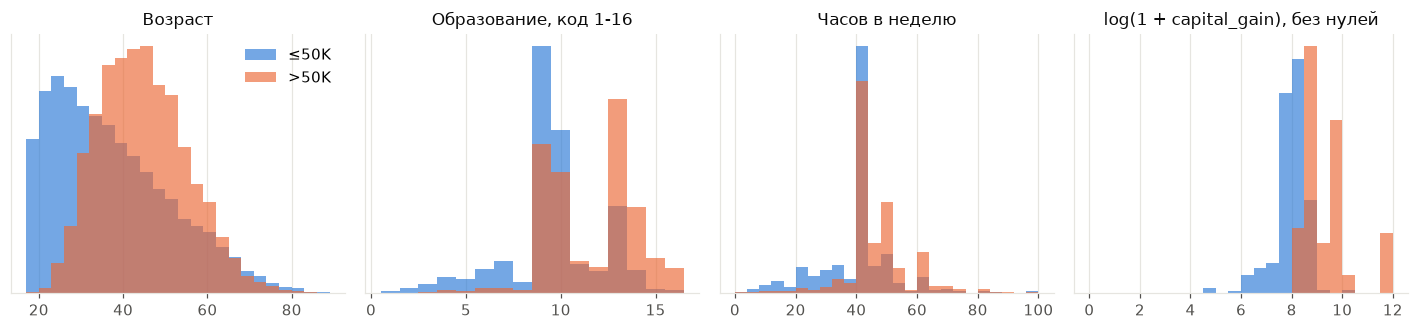

In [4]:
# Распределения числовых признаков по классам
low, high = train_eda[train_eda[D.TARGET] == 0], train_eda[train_eda[D.TARGET] == 1]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.1))
for ax, col, bins, title in [
    (axes[0], "age", np.arange(17, 92, 3), "Возраст"),
    (axes[1], "education_num", np.arange(0.5, 17.5, 1), "Образование, код 1-16"),
    (axes[2], "hours_per_week", np.arange(0, 102, 4), "Часов в неделю"),
]:
    ax.hist(low[col], bins=bins, density=True, color=BLUE, alpha=0.65, label="≤50K")
    ax.hist(high[col], bins=bins, density=True, color=ORANGE, alpha=0.65, label=">50K")
    ax.set_title(title); ax.set_yticks([])
bins = np.linspace(0, 12, 25)
axes[3].hist(np.log1p(low.loc[low.capital_gain > 0, "capital_gain"]), bins=bins, density=True, color=BLUE, alpha=0.65, label="≤50K")
axes[3].hist(np.log1p(high.loc[high.capital_gain > 0, "capital_gain"]), bins=bins, density=True, color=ORANGE, alpha=0.65, label=">50K")
axes[3].set_title("log(1 + capital_gain), без нулей"); axes[3].set_yticks([])
axes[0].legend(loc="upper right")
plt.tight_layout(); plt.savefig(FIGURES / "eda_numeric.png"); plt.show()

**Вывод.** Люди с высоким доходом старше, образованнее и больше работают, но классы сильно перекрываются: ни один признак в одиночку задачу не решает. На 40 часах стоит большой пик, поэтому выделены флаги `overtime` и `part_time`. Главное наблюдение: `capital_gain` немонотонен. При нуле доля >50K равна 0.206, при значениях от 1 до 5118 она ниже (0.162), а от 5119 резко 0.949. Такой порог важен дальше.

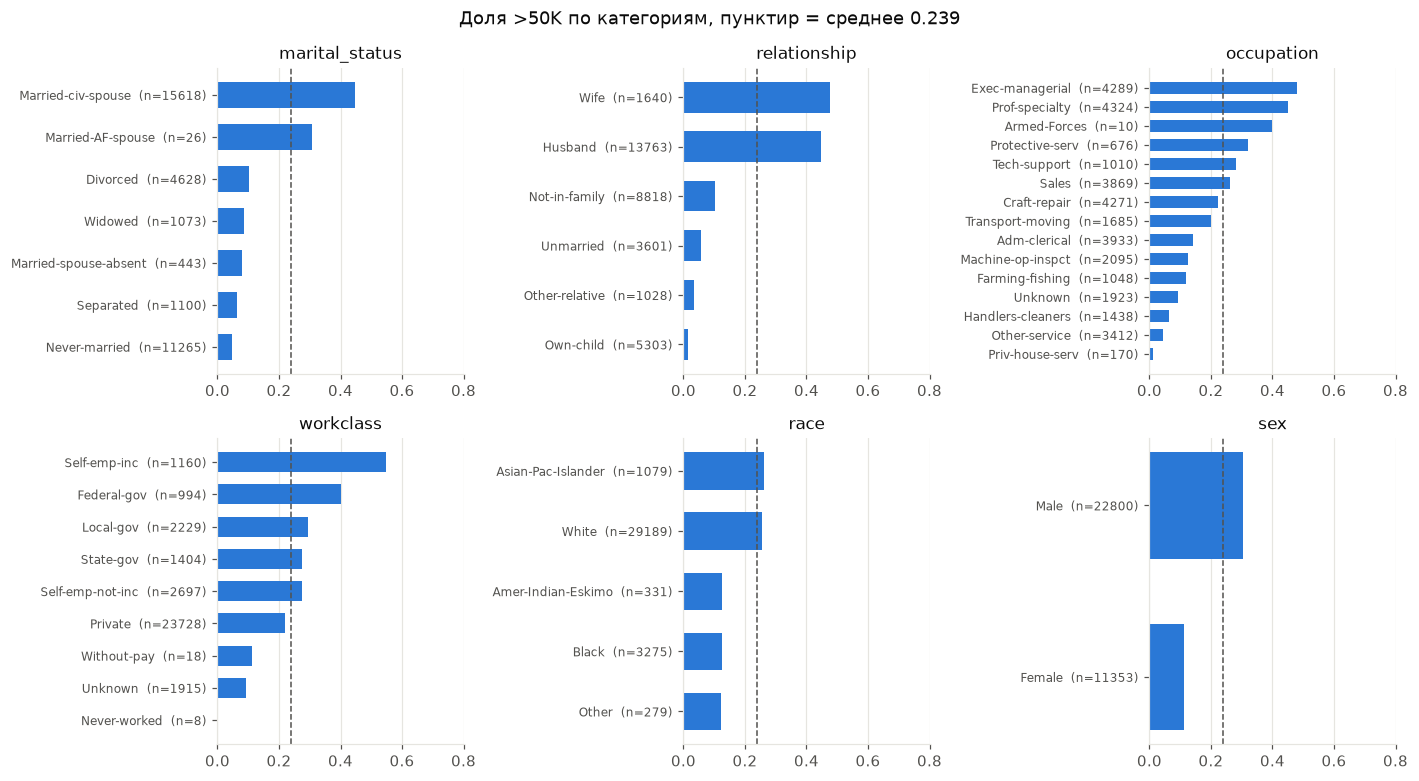

In [5]:
# Доля высокого дохода внутри каждой категории. Пунктир = средняя доля по train
overall = train_eda[D.TARGET].mean()
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2))
for ax, col in zip(axes.flat, ["marital_status", "relationship", "occupation", "workclass", "race", "sex"]):
    stat = train_eda.groupby(col, observed=True)[D.TARGET].agg(["mean", "size"]).sort_values("mean")
    labels = [f"{i}  (n={int(n)})" for i, n in zip(stat.index, stat["size"])]
    ax.barh(labels, stat["mean"], color=BLUE, height=0.62)
    ax.axvline(overall, color=MUTED, linestyle="--", linewidth=1)
    ax.set_title(col); ax.set_xlim(0, 0.8); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8)
fig.suptitle(f"Доля >50K по категориям, пунктир = среднее {overall:.3f}", color=TEXT, fontsize=12)
plt.tight_layout(); plt.savefig(FIGURES / "eda_categories.png"); plt.show()

**Вывод.** Сильнее всего разделяют семейное положение (женатые 0.45, остальные ниже 0.11) и роль в семье. Различия по профессиям тоже велики: от 0.48 у `Exec-managerial` до почти нуля у `Priv-house-serv`. Некоторые категории очень малы (`Never-worked`, n=8; `Armed-Forces`, n=10), поэтому редкие склеиваются. Разрыв по полу (0.30 и 0.11) и по расе отражает неравенство в данных 1994 года и не означает причину, это нужно проверить в ошибках модели.

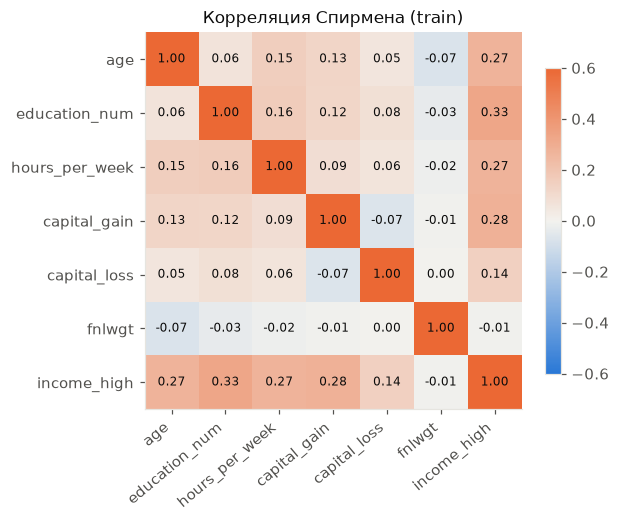

In [6]:
# Spearman показывает монотонную связь и не боится длинных хвостов
num_view = train_eda[["age", "education_num", "hours_per_week", "capital_gain", "capital_loss", "fnlwgt", D.TARGET]]
corr = num_view.corr(method="spearman")
cmap = LinearSegmentedColormap.from_list("div", [BLUE, "#f3f2ee", ORANGE])  # синий и оранжевый, середина нейтральная
fig, ax = plt.subplots(figsize=(5.8, 4.8))
im = ax.imshow(corr, cmap=cmap, vmin=-0.6, vmax=0.6)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right"); ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color=TEXT)
fig.colorbar(im, shrink=0.8); ax.set_title("Корреляция Спирмена (train)")
plt.tight_layout(); plt.savefig(FIGURES / "eda_correlation.png"); plt.show()

**Вывод.** Числовые признаки слабо связаны между собой (все |r| ≤ 0.16), сильной мультиколлинеарности в исходных числах нет. С целью сильнее всего связаны `education_num` (0.33), `capital_gain` (0.28), `age` и `hours_per_week` (0.27). `fnlwgt` даёт −0.01, что подтверждает решение его убрать.

## 4. Очистка и feature engineering

**Очистка (`src/data.py: clean`):** точные дубли убраны до разбиения, чтобы одна строка не попала и в train, и в test. Пропуски стали категорией `Unknown`, потому что сам факт пропуска связан с доходом. Выбросы не удалялись: значения на потолке анкеты настоящие, для них есть отдельный флаг.

**Отброшены:** `fnlwgt` (вес выборки, а не свойство человека) и `education` (дублирует `education_num`).

**Новые признаки (`add_features`):**

| Признак | Формула | Зачем |
|---|---|---|
| `age_squared` | age² | Доход сначала растёт, потом падает, линейной модели нужна парабола |
| `experience` | age − education_num − 6 | Потенциальный стаж (идея из уравнения Минцера) |
| `edu_x_hours` | education_num × hours | Взаимодействие: образование окупается вместе с часами |
| `log_capital_gain/loss` | log(1+x) | Сжимает хвост до 99999, иначе масштабирование сломает шкалу |
| `has_capital_gain/loss` | x > 0 | Отделяет «совсем нет» от «мало» |
| `capital_gain_capped` | x = 99999 | Потолок анкеты, реальное значение неизвестно |
| `overtime`, `part_time` | hours > 40, hours < 35 | Режим работы вместо сырых часов |
| `is_married` | семейное положение | Сильнейший сигнал EDA одним битом |
| `is_us` | страна = США | 90% строк: остальные страны по отдельности слишком редки |

Все они считаются по одной строке, поэтому утечки здесь нет. Дают ли они пользу, проверяется не верой, а экспериментом: одна и та же модель с признаками и без них.

In [7]:
df = D.add_features(df_clean)
new_cols = [c for c in D.FE_NUM_COLS if c not in D.RAW_NUM_COLS]
display(df[["age", "education_num", "hours_per_week", "capital_gain", "marital_status"] + new_cols].sample(4, random_state=SEED).T)

train_df, val_df, test_df = D.split_data(df)
display(D.split_summary(train_df, val_df, test_df))
D.split_summary(train_df, val_df, test_df).to_csv(TABLES / "splits.csv", index=False)
y_train, y_val, y_test = (d[D.TARGET].to_numpy() for d in (train_df, val_df, test_df))

# Сила каждого числового признака в одиночку. Значение |AUC-0.5| показывает, насколько признак различает классы
auc_rows = [{"признак": c, "новый": c in new_cols, "ROC-AUC": roc_auc_score(y_train, train_df[c])} for c in D.FE_NUM_COLS]
auc = pd.DataFrame(auc_rows).assign(сила=lambda t: (t["ROC-AUC"] - 0.5).abs()).sort_values("сила", ascending=False)
auc.to_csv(TABLES / "feature_auc.csv", index=False); display(auc)

,3168,25257,33645,29906
age,54,43,29,47
education_num,10,13,13,13
hours_per_week,40,44,45,40
capital_gain,0,0,8614,0
marital_status,Married-civ-spouse,Divorced,Never-married,Married-civ-spouse
age_squared,2916,1849,841,2209
experience,38,24,10,28
edu_x_hours,400,572,585,520
log_capital_gain,0.000,0.000,9.061,0.000
log_capital_loss,0.000,0.000,0.000,0.000


,сплит,строк,>50K,доля
0,train,34153,8177,0.239
1,val,7318,1752,0.239
2,test,7319,1752,0.239


,признак,новый,ROC-AUC,сила
13,is_married,True,0.761,0.261
5,edu_x_hours,True,0.755,0.255
2,education_num,False,0.715,0.215
0,age,False,0.682,0.182
1,age_squared,True,0.682,0.182
3,hours_per_week,False,0.672,0.172
4,experience,True,0.644,0.144
11,overtime,True,0.630,0.130
6,log_capital_gain,True,0.589,0.089
8,has_capital_gain,True,0.585,0.085


**Вывод.** В одиночку сильнейшими оказались новые признаки `is_married` (AUC 0.76) и `edu_x_hours` (0.75): они сильнее любого исходного числа. Флаги `is_us` и `capital_gain_capped` в одиночку слабые, но это не значит бесполезные: второй касается малой группы, где модель всегда права. Вклад всего набора проверяем ниже экспериментом.

## 5. Предобработка
Все преобразования, которые учатся на данных, обучаются **только на train** (`src/preprocessing.py`):

- **StandardScaler** для чисел. Сети учатся градиентным спуском, и признак с большой шкалой иначе доминирует в шаге.
- **One-hot** для sklearn-моделей и двух первых сетей. Категории реже 20 строк в train склеиваются в одну.
- **Индексы категорий** для своей сети: вместо столбцов one-hot обучаемые векторы (embeddings). Индекс 0 зарезервирован под категорию, которой не было в train.

In [8]:
# Два набора признаков: с инженерией и без, чтобы измерить её вклад
SETS = {"FE": D.FE_NUM_COLS, "RAW": D.RAW_NUM_COLS}
onehot_pre = {k: P.make_onehot_preprocessor(v, D.CAT_COLS).fit(train_df) for k, v in SETS.items()}
X_tr, X_va, X_te = (onehot_pre["FE"].transform(d).astype(np.float32) for d in (train_df, val_df, test_df))

emb_pre = P.EmbeddingPreprocessor(D.FE_NUM_COLS, D.CAT_COLS).fit(train_df)
tr_emb, va_emb, te_emb = (emb_pre.transform(d) for d in (train_df, val_df, test_df))
cards = emb_pre.cardinalities()

print("One-hot вход:", X_tr.shape, "| embedding-вход: чисел", tr_emb[0].shape[1], "категорий", tr_emb[1].shape[1])
print("Размеры словарей:", dict(zip(D.CAT_COLS, cards)))
print("Размеры embedding:", dict(zip(D.CAT_COLS, [N.embedding_dim(c) for c in cards])))
# Проверка утечки: на train среднее около 0, на val немного отличается, потому что scaler не видел val
print("Среднее первого числового признака: train", round(float(X_tr[:, 0].mean()), 4), "| val", round(float(X_va[:, 0].mean()), 4))
display(pd.DataFrame(X_tr[:3, :6], columns=onehot_pre["FE"].get_feature_names_out()[:6]))

One-hot вход: (34153, 93) | embedding-вход: чисел 15 категорий 7
Размеры словарей: {'workclass': 9, 'marital_status': 8, 'occupation': 16, 'relationship': 7, 'race': 6, 'sex': 3, 'native_country': 36}
Размеры embedding: {'workclass': 5, 'marital_status': 5, 'occupation': 8, 'relationship': 5, 'race': 4, 'sex': 3, 'native_country': 12}
Среднее первого числового признака: train -0.0 | val -0.0078


,num__age,num__age_squared,num__education_num,num__hours_per_week,num__experience,num__edu_x_hours
0,1.486,1.521,2.307,0.773,1.041,2.187
1,-1.071,-0.935,-0.420,0.773,-0.981,0.215
2,0.171,-0.001,-1.199,-0.034,0.391,-0.743


## 6. Baseline: модели из прошлых лекций
Цепочка от наивной модели к сильной. Dummy показывает нижнюю планку, остальные показывают, что нужно обойти сети. Порог F1 у каждой модели подобран на val.

In [9]:
rows, base_scores = [], {}
for name, model in M.baseline_models(SEED).items():
    pipe = make_pipeline(P.make_onehot_preprocessor(D.FE_NUM_COLS, D.CAT_COLS), model)
    fit_X, fit_y = train_df, y_train
    if name.startswith("SVM"):  # подвыборка: SVC растёт примерно квадратично по числу строк
        fit_X, _, fit_y, _ = train_test_split(train_df, y_train, train_size=M.SVM_TRAIN_SIZE, stratify=y_train, random_state=SEED)
    start = time.perf_counter()
    pipe.fit(fit_X, fit_y)
    fit_time = time.perf_counter() - start
    scores = M.scores_of(pipe, val_df)
    base_scores[name] = (pipe, scores)
    thr = 0.5 if name.startswith("Dummy") else X.best_threshold(y_val, scores)
    rows.append({"модель": name, **X.evaluate(y_val, scores, thr), "время, с": fit_time})
baseline_table = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False)
baseline_table.to_csv(TABLES / "baselines_val.csv", index=False); display(baseline_table)

,модель,PR-AUC,ROC-AUC,F1,Precision,Recall,Accuracy,"время, с"
7,Gradient Boosting,0.828,0.927,0.728,0.728,0.729,0.870,26.798
6,Random Forest,0.801,0.915,0.711,0.673,0.752,0.853,3.824
2,Logistic Regression,0.783,0.912,0.700,0.627,0.792,0.837,0.929
4,Decision Tree,0.763,0.903,0.684,0.672,0.696,0.846,0.684
5,SVM RBF (10k строк),0.742,0.884,0.677,0.597,0.783,0.821,4.607
3,kNN (k=25),0.726,0.893,0.674,0.651,0.699,0.838,0.288
1,Naive Bayes,0.639,0.854,0.648,0.565,0.759,0.802,0.319
0,Dummy (частый класс),0.239,0.500,0.000,0.000,0.000,0.761,0.293


**Вывод.** Все модели обходят Dummy (0.239) с большим запасом. Лучший baseline это бустинг: PR-AUC 0.828. Логистическая регрессия даёт 0.783 за 0.4 с, и это хорошая планка для сетей. SVM с подвыборкой 10 тысяч строк отстаёт (0.742), часть потери объясняется меньшим объёмом данных. У Dummy accuracy 0.761 при нуле найденных людей с высоким доходом, поэтому accuracy здесь не подходит как главная метрика.

### Вклад feature engineering
Один эксперимент меняет одно: та же модель, только другой набор числовых признаков.

In [10]:
fe_rows = []
for name in ["Logistic Regression", "Gradient Boosting"]:
    for set_name, cols in SETS.items():
        pipe = make_pipeline(P.make_onehot_preprocessor(cols, D.CAT_COLS), M.baseline_models(SEED)[name]).fit(train_df, y_train)
        s = M.scores_of(pipe, val_df)
        fe_rows.append({"модель": name, "признаки": set_name, "PR-AUC": average_precision_score(y_val, s), "ROC-AUC": roc_auc_score(y_val, s)})
fe_table = pd.DataFrame(fe_rows); display(fe_table)
fe_table.to_csv(TABLES / "fe_effect.csv", index=False)

,модель,признаки,PR-AUC,ROC-AUC
0,Logistic Regression,FE,0.783,0.912
1,Logistic Regression,RAW,0.763,0.905
2,Gradient Boosting,FE,0.828,0.927
3,Gradient Boosting,RAW,0.827,0.927


**Вывод.** Инженерия признаков заметно помогла линейной модели (0.763 → 0.783): квадрат возраста и взаимодействия ей самой недоступны. Бустингу она почти не нужна (0.827 → 0.828): деревья сами находят пороги и взаимодействия.

### Тюнинг лучшего baseline
Сети будут настраиваться, поэтому и сильнейшему baseline даём случайный поиск по 15 конфигурациям. Иначе сравнение было бы нечестным.

In [11]:
space = {"learning_rate": [0.03, 0.05, 0.1], "max_iter": [200, 400, 800], "max_leaf_nodes": [15, 31, 63],
         "min_samples_leaf": [20, 50, 100], "l2_regularization": [0.0, 1.0, 10.0]}
hgb_rows = []
for params in ParameterSampler(space, n_iter=15, random_state=SEED):
    model = HistGradientBoostingClassifier(random_state=SEED, **params).fit(X_tr, y_train)
    hgb_rows.append({**params, "val PR-AUC": average_precision_score(y_val, model.predict_proba(X_va)[:, 1])})
hgb_search = pd.DataFrame(hgb_rows).sort_values("val PR-AUC", ascending=False)
hgb_search.to_csv(TABLES / "hgb_search.csv", index=False); display(hgb_search.head(5))
best_hgb_params = {k: (v.item() if hasattr(v, "item") else v) for k, v in hgb_search.iloc[0].drop("val PR-AUC").to_dict().items()}
best_hgb_params["max_iter"] = int(best_hgb_params["max_iter"]); best_hgb_params["max_leaf_nodes"] = int(best_hgb_params["max_leaf_nodes"]); best_hgb_params["min_samples_leaf"] = int(best_hgb_params["min_samples_leaf"])
print(best_hgb_params)

,min_samples_leaf,max_leaf_nodes,max_iter,learning_rate,l2_regularization,val PR-AUC
7,20,63,400,0.100,1.000,0.827
0,20,63,800,0.030,0.000,0.826
1,20,63,200,0.030,0.000,0.826
8,20,15,400,0.030,0.000,0.825
10,20,15,800,0.050,0.000,0.824


{'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 400, 'learning_rate': 0.1, 'l2_regularization': 1.0}


**Вывод.** Поиск не обошёл настройки по умолчанию: лучшая из 15 конфигураций даёт 0.827, а значения по умолчанию 0.828. Разница мала, то есть бустинг уже у своего потолка на этих данных. По правилу выбора дальше сравниваем лучшую версию на val, то есть версию по умолчанию.

## 7. Нейронные сети
Три типа из задания (код в `src/nn_models.py`), PyTorch. Обучение общее (`src/train.py`):

- **Loss:** `BCEWithLogitsLoss` (log loss для двух классов).
- **Оптимизатор:** AdamW, weight decay задаёт L2-подобную регуляризацию.
- **Расписание:** `ReduceLROnPlateau`, шаг вдвое меньше, если val loss не падает 3 эпохи.
- **Остановка:** нет улучшения val loss 8 эпох, возвращаем лучшие веса.
- **Batch** 256, максимум 60 эпох, вычисления на CPU: для маленьких табличных сетей этого достаточно и результат воспроизводим.

### Проверка кода перед обучением
Исправная сеть обязана выучить 64 строки почти наизусть. Если не может, ошибка в коде, а не в данных.

In [12]:
own_defaults = dict(n_num=tr_emb[0].shape[1], cardinalities=cards)
check_rows = []
for kind, params, inputs in [
    ("simple", {"n_inputs": X_tr.shape[1]}, [X_tr[:64]]),
    ("deep", {"n_inputs": X_tr.shape[1]}, [X_tr[:64]]),
    ("own", own_defaults, [tr_emb[0][:64], tr_emb[1][:64]]),
]:
    first, last = T.overfit_check(kind, params, inputs, y_train[:64])
    check_rows.append({"сеть": kind, "loss в начале": first, "loss после 500 шагов": last})
display(pd.DataFrame(check_rows))

,сеть,loss в начале,loss после 500 шагов
0,simple,0.731,0.000
1,deep,0.658,0.001
2,own,0.818,0.000


### Подбор конфигураций
Выбор по PR-AUC на val при seed 42. Бюджет поиска разный: у простой сети почти нечего настраивать, а у своей параметров больше всего, и в отчёте это указано.

In [13]:
def cfg(kind, params, emb=False, lr=1e-3, weight_decay=1e-4, seed=SEED):
    """Один запуск обучения: какая сеть, какой вход, какие настройки."""
    tr, va = (list(tr_emb), list(va_emb)) if emb else ([X_tr], [X_va])
    return dict(kind=kind, params=params, train_inputs=tr, y_train=y_train, val_inputs=va, y_val=y_val,
                lr=lr, weight_decay=weight_decay, seed=seed)

n_inputs = X_tr.shape[1]
simple_grid = [{"n_inputs": n_inputs, "hidden": h} for h in (16, 64, 256)]
deep_grid = [{"n_inputs": n_inputs, "hidden": h, "dropout": p}
             for h in ((128, 64), (256, 128, 64, 32), (512, 256, 128, 64)) for p in (0.1, 0.3)]
own_space = {"d": [64, 128, 256], "n_blocks": [2, 3, 4], "dropout": [0.1, 0.2, 0.3], "lr": [1e-3, 2e-3], "weight_decay": [1e-5, 1e-4, 1e-3]}
own_grid = list(ParameterSampler(own_space, n_iter=12, random_state=SEED))

start = time.perf_counter()
configs = ([cfg("simple", p) for p in simple_grid] + [cfg("deep", p) for p in deep_grid]
           + [cfg("own", {**own_defaults, "d": g["d"], "n_blocks": g["n_blocks"], "dropout": g["dropout"]}, emb=True,
                  lr=g["lr"], weight_decay=g["weight_decay"]) for g in own_grid])
search_runs = T.run_many(configs)
print(f"{len(configs)} запусков за {time.perf_counter() - start:.0f} с")

def describe(c):
    keep = {k: v for k, v in c["params"].items() if k not in ("n_inputs", "n_num", "cardinalities")}
    return {"сеть": c["kind"], **keep, "lr": c["lr"], "wd": c["weight_decay"]}

search = pd.DataFrame([
    {**describe(c), "val PR-AUC": average_precision_score(y_val, r["val_scores"]),
     "best_epoch": r["best_epoch"], "time, s": r["train_time"], "idx": i}
    for i, (c, r) in enumerate(zip(configs, search_runs))
]).sort_values(["сеть", "val PR-AUC"], ascending=[True, False])
search.drop(columns="idx").to_csv(TABLES / "nn_search.csv", index=False)
display(search.drop(columns="idx").astype({"hidden": str}))
best_cfg = {k: configs[int(search[search["сеть"] == k].iloc[0]["idx"])] for k in ("simple", "deep", "own")}
print({k: describe(v) for k, v in best_cfg.items()})

21 запусков за 197 с


,сеть,hidden,lr,wd,val PR-AUC,best_epoch,"time, s",dropout,d,n_blocks
4,deep,"(128, 64)",0.001,0.000,0.784,19,11.192,0.300,NaN,NaN
3,deep,"(128, 64)",0.001,0.000,0.782,11,7.531,0.100,NaN,NaN
6,deep,"(256, 128, 64, 32)",0.001,0.000,0.780,14,21.018,0.300,NaN,NaN
8,deep,"(512, 256, 128, 64)",0.001,0.000,0.779,10,35.213,0.300,NaN,NaN
5,deep,"(256, 128, 64, 32)",0.001,0.000,0.778,6,13.055,0.100,NaN,NaN
7,deep,"(512, 256, 128, 64)",0.001,0.000,0.774,3,19.205,0.100,NaN,NaN
16,own,NaN,0.002,0.000,0.786,45,106.264,0.300,64.000,4.000
15,own,NaN,0.002,0.001,0.786,24,65.694,0.300,128.000,2.000
14,own,NaN,0.002,0.001,0.786,38,58.059,0.200,64.000,2.000
17,own,NaN,0.002,0.000,0.785,31,84.828,0.300,128.000,2.000


{'simple': {'сеть': 'simple', 'hidden': 64, 'lr': 0.001, 'wd': 0.0001}, 'deep': {'сеть': 'deep', 'hidden': (128, 64), 'dropout': 0.3, 'lr': 0.001, 'wd': 0.0001}, 'own': {'сеть': 'own', 'd': 64, 'n_blocks': 4, 'dropout': 0.3, 'lr': 0.002, 'wd': 1e-05}}


**Вывод.** Лучшие значения: простая сеть 64 нейрона (0.779), сложная (128, 64) с dropout 0.3 (0.784), своя d=64, 4 блока, dropout 0.3 (0.786). Весь разброс конфигураций сверху упирается в 0.78-0.79, что почти равно логистической регрессии (0.783). Большие сети (256 и 512 нейронов) не лучше маленьких: мощности хватает, не хватает чего-то другого.

### Диагностика: почему сети отстают от бустинга
Поиск упёрся в потолок около 0.78, это уровень логистической регрессии, а бустинг даёт 0.83. Больше параметров не помогает, значит, причина не в размере сети.

**Гипотеза:** в EDA `capital_gain` выглядит как резкий порог: выше некоторых значений почти все получают больше 50K. Дерево режет точно по порогу, а сеть получает один гладкий столбец логарифма. Если это так, без столбцов капитала разрыв должен почти исчезнуть.

In [14]:
NO_CAP = [c for c in D.FE_NUM_COLS if "capital" not in c]
def hgb_val(cols):
    pre = P.make_onehot_preprocessor(cols, D.CAT_COLS).fit(train_df)
    model = HistGradientBoostingClassifier(random_state=SEED).fit(pre.transform(train_df), y_train)
    return average_precision_score(y_val, model.predict_proba(pre.transform(val_df))[:, 1])

nc_pre = P.EmbeddingPreprocessor(NO_CAP, D.CAT_COLS).fit(train_df)
nc_tr, nc_va = nc_pre.transform(train_df), nc_pre.transform(val_df)
own_cfg = best_cfg["own"]
nc_cfg = {**own_cfg, "params": {**own_cfg["params"], "n_num": nc_tr[0].shape[1], "cardinalities": nc_pre.cardinalities()},
          "train_inputs": list(nc_tr), "val_inputs": list(nc_va)}
gap_runs = T.run_many([{**c, "seed": s} for c in (own_cfg, nc_cfg) for s in FINAL_SEEDS[:3]])
own_with = np.mean([average_precision_score(y_val, r["val_scores"]) for r in gap_runs[:3]])
own_without = np.mean([average_precision_score(y_val, r["val_scores"]) for r in gap_runs[3:]])
gap = pd.DataFrame({"набор": ["с капиталом", "без капитала"], "Бустинг": [hgb_val(D.FE_NUM_COLS), hgb_val(NO_CAP)], "Своя сеть": [own_with, own_without]})
gap["разрыв"] = gap["Бустинг"] - gap["Своя сеть"]
gap.to_csv(TABLES / "capital_gap.csv", index=False); display(gap)

,набор,Бустинг,Своя сеть,разрыв
0,с капиталом,0.828,0.784,0.044
1,без капитала,0.714,0.704,0.011


**Вывод.** Гипотеза подтвердилась. С капиталом разрыв 0.044, без него 0.011: разрыв сократился в 4 раза. Значит, основной проигрыш сетей связан с тем, как они видят `capital_gain`. Это видно и по числам: при значениях от 1 до 5118 доля >50K ниже, чем при нуле, а затем резко прыгает. Гладкий логарифм такую форму не передаёт.

### Улучшение: кусочно-линейное кодирование чисел (PLE)
Вместо одного столбца каждое непрерывное число становится набором столбцов-интервалов (`PiecewiseLinearEncoder`, Gorishniy и др., 2022). Границы интервалов находит решающее дерево на **train**, поэтому утечки нет.

Пример для интервалов [0, 5], [5, 10], [10, 20] и `x = 7`: получаем `[1, 0.4, 0]`. Первый интервал пройден, второй пройден на 40%, третий не начат.

Это одно изменение входа. Сеть, оптимизатор и остальные признаки те же. Чтобы отделить вклад входа от вклада архитектуры, PLE проверяем на всех трёх сетях.

In [15]:
ple = P.PiecewiseLinearEncoder(D.FE_PLE_COLS).fit(train_df, y_train)
P_tr, P_va, P_te = (ple.transform(d) for d in (train_df, val_df, test_df))
print("Интервалов по признакам:", {c: len(e) - 1 for c, e in ple.edges_.items()})
print("Границы log_capital_gain в долларах:", np.round(np.expm1(ple.edges_["log_capital_gain"])).astype(int).tolist())
ple_example = pd.DataFrame(P_tr[:3][:, :len(ple.edges_["age"]) - 1], index=train_df["age"].iloc[:3].rename("age")).round(2)
display(ple_example)

# Своя сеть: числа и PLE идут вместе. Простая и сложная: те же столбцы рядом с one-hot
X_tr_ple, X_va_ple, X_te_ple = (np.hstack(p) for p in ((X_tr, P_tr), (X_va, P_va), (X_te, P_te)))
own_tr = [np.hstack([tr_emb[0], P_tr]), tr_emb[1]]
own_va = [np.hstack([va_emb[0], P_va]), va_emb[1]]
own_te = [np.hstack([te_emb[0], P_te]), te_emb[1]]
own_ple_cfg = {**own_cfg, "params": {**own_cfg["params"], "n_num": own_tr[0].shape[1]}, "train_inputs": own_tr, "val_inputs": own_va}

def with_ple(c):
    n = X_tr_ple.shape[1]
    return {**c, "params": {**c["params"], "n_inputs": n}, "train_inputs": [X_tr_ple], "val_inputs": [X_va_ple]}

Интервалов по признакам: {'age': 16, 'education_num': 16, 'hours_per_week': 16, 'log_capital_gain': 16, 'log_capital_loss': 14, 'experience': 16, 'edu_x_hours': 16}
Границы log_capital_gain в долларах: [0, 10, 3048, 3120, 4241, 4401, 4973, 5119, 5315, 7052, 7436, 8290, 10030, 10585, 21022, 58391, 99999]


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
age,,,,,,,,,,,,,,,,
59,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.900,0.000,0.000,0.000,0.000
24,1.000,0.750,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
41,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.170,0.000,0.000,0.000,0.000,0.000,0.000


### Финальные версии: по 5 seed
Сеть зависит от случайной инициализации. Одно число может быть удачей, поэтому каждую версию запускаем 5 раз и смотрим среднее и разброс.

**Своя сеть** в итоге = embeddings + PLE + residual-блоки + wide-часть.

,сеть,параметров,val PR-AUC,std PR-AUC,val ROC-AUC,эпох до лучшей,"время, с"
0,Простая сеть,6081,0.780,0.001,0.912,43.400,5.881
1,Сложная сеть,20737,0.782,0.001,0.912,20.200,9.388
2,Простая сеть + PLE,13121,0.813,0.001,0.921,37.600,6.973
3,Сложная сеть + PLE,34817,0.811,0.001,0.920,14.600,8.674
4,Своя сеть,78685,0.814,0.003,0.922,48.000,48.997


Лучшие настройки: {'simple': {'сеть': 'simple', 'hidden': 64, 'lr': 0.001, 'wd': 0.0001}, 'deep': {'сеть': 'deep', 'hidden': (128, 64), 'dropout': 0.3, 'lr': 0.001, 'wd': 0.0001}, 'own': {'сеть': 'own', 'd': 64, 'n_blocks': 4, 'dropout': 0.3, 'lr': 0.002, 'wd': 1e-05}}


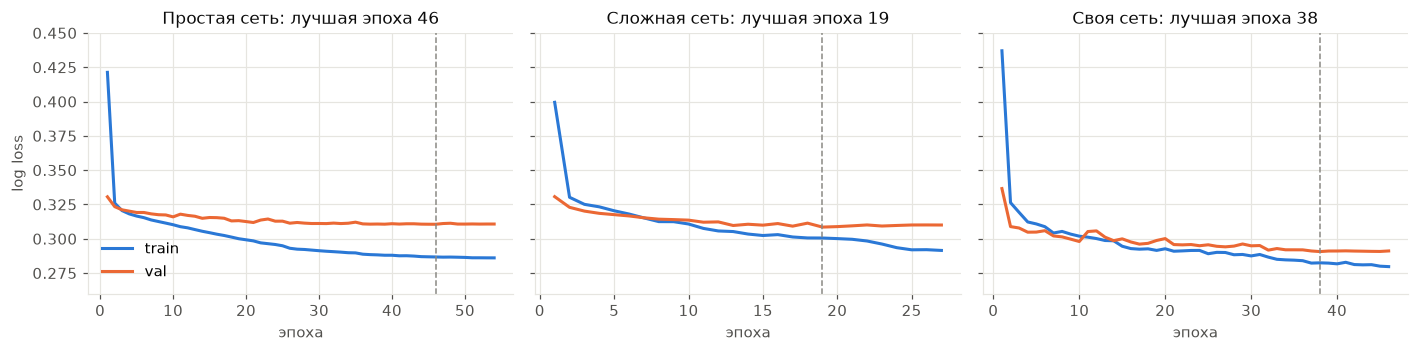

In [16]:
def with_seed(c, seed):
    return {**c, "seed": seed}

NAMES = {"simple": "Простая сеть", "deep": "Сложная сеть", "simple_ple": "Простая сеть + PLE", "deep_ple": "Сложная сеть + PLE", "own": "Своя сеть"}
final_base = {"simple": best_cfg["simple"], "deep": best_cfg["deep"], "simple_ple": with_ple(best_cfg["simple"]),
              "deep_ple": with_ple(best_cfg["deep"]), "own": own_ple_cfg}
FINAL_VAL = {"simple": [X_va], "deep": [X_va], "simple_ple": [X_va_ple], "deep_ple": [X_va_ple], "own": own_va}
FINAL_TEST = {"simple": [X_te], "deep": [X_te], "simple_ple": [X_te_ple], "deep_ple": [X_te_ple], "own": own_te}
keys = list(final_base)
flat = T.run_many([with_seed(final_base[k], s) for k in keys for s in FINAL_SEEDS])
final_runs = {k: flat[i * 5 : (i + 1) * 5] for i, k in enumerate(keys)}

def param_count(run):
    return N.count_parameters(T.restore(run))

nn_rows = []
for k, runs in final_runs.items():
    pr = [average_precision_score(y_val, r["val_scores"]) for r in runs]
    roc = [roc_auc_score(y_val, r["val_scores"]) for r in runs]
    nn_rows.append({"сеть": NAMES[k], "параметров": param_count(runs[0]), "val PR-AUC": np.mean(pr), "std PR-AUC": np.std(pr),
                    "val ROC-AUC": np.mean(roc), "эпох до лучшей": np.mean([r["best_epoch"] for r in runs]),
                    "время, с": np.mean([r["train_time"] for r in runs])})
nn_table = pd.DataFrame(nn_rows); nn_table.to_csv(TABLES / "nn_final_val.csv", index=False); display(nn_table)
print("Лучшие настройки:", {k: describe(final_base[k]) for k in ("simple", "deep", "own")})

# Кривые обучения seed 42: где сеть начинает переобучаться
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for ax, k in zip(axes, ("simple", "deep", "own")):
    run = final_runs[k][0]; h = pd.DataFrame(run["history"])
    ax.plot(h.epoch, h.train_loss, color=BLUE, label="train")
    ax.plot(h.epoch, h.val_loss, color=ORANGE, label="val")
    ax.axvline(run["best_epoch"], color=GRAY, linestyle="--", linewidth=1)
    ax.set_title(f"{NAMES[k]}: лучшая эпоха {run['best_epoch']}"); ax.set_xlabel("эпоха")
axes[0].set_ylabel("log loss"); axes[0].legend()
axes[0].set_ylim(0.26, 0.45)
plt.tight_layout(); plt.savefig(FIGURES / "learning_curves.png"); plt.show()

**Вывод.** PLE поднял все сети примерно на 0.03: простую с 0.780 до 0.813, сложную с 0.782 до 0.811, свою до 0.814. Своя сеть лучшая на val, но простая + PLE отстаёт всего на 0.001 при 13 тысячах параметров против 79 и примерно в 7 раз быстрее. Главный вклад дал вход, а не архитектура. Кривые: разрыв train и val у своей сети небольшой, переобучение слабое. Лучшая эпоха у своей сети поздняя (38), потому что Dropout замедляет обучение и регуляризует.

### Ablation своей сети: что даёт каждая часть
Из финальной сети убираем по одной части (3 seed на вариант). Глубина 12 блоков проверяет, нужны ли skip-соединения там, где сеть действительно глубокая.

In [17]:
base_p = own_ple_cfg["params"]
# Без feature engineering: только исходные числа и PLE по ним
raw_emb = P.EmbeddingPreprocessor(D.RAW_NUM_COLS, D.CAT_COLS).fit(train_df)
raw_ple = P.PiecewiseLinearEncoder(D.RAW_NUM_COLS).fit(train_df, y_train)
raw_tr, raw_va = raw_emb.transform(train_df), raw_emb.transform(val_df)
raw_inputs_tr = [np.hstack([raw_tr[0], raw_ple.transform(train_df)]), raw_tr[1]]
raw_inputs_va = [np.hstack([raw_va[0], raw_ple.transform(val_df)]), raw_va[1]]
variants = {
    "база": own_ple_cfg,
    "без PLE": own_cfg,
    "без feature engineering": {**own_ple_cfg, "params": {**base_p, "n_num": raw_inputs_tr[0].shape[1], "cardinalities": raw_emb.cardinalities()},
                                "train_inputs": raw_inputs_tr, "val_inputs": raw_inputs_va},
    "без wide-части": {**own_ple_cfg, "params": {**base_p, "use_wide": False}},
    "без skip-соединений": {**own_ple_cfg, "params": {**base_p, "use_skip": False}},
    "one-hot вместо embeddings": {**own_ple_cfg, "params": {**base_p, "learned_embeddings": False}},
    "без dropout": {**own_ple_cfg, "params": {**base_p, "dropout": 0.0}},
    "12 блоков, со skip": {**own_ple_cfg, "params": {**base_p, "n_blocks": 12}},
    "12 блоков, без skip": {**own_ple_cfg, "params": {**base_p, "n_blocks": 12, "use_skip": False}},
}
abl_seeds = FINAL_SEEDS[:3]
abl_runs = T.run_many([with_seed(c, s) for c in variants.values() for s in abl_seeds])
abl_rows = []
for i, name in enumerate(variants):
    chunk = abl_runs[i * 3 : (i + 1) * 3]
    pr = [average_precision_score(y_val, r["val_scores"]) for r in chunk]
    abl_rows.append({"вариант": name, "val PR-AUC": np.mean(pr), "std": np.std(pr),
                     "val loss": np.mean([r["best_val_loss"] for r in chunk]),
                     "эпох": np.mean([r["best_epoch"] for r in chunk]), "параметров": param_count(chunk[0])})
abl = pd.DataFrame(abl_rows)
abl["к базе"] = abl["val PR-AUC"] - abl.loc[0, "val PR-AUC"]
abl.to_csv(TABLES / "ablation.csv", index=False); display(abl)

,вариант,val PR-AUC,std,val loss,эпох,параметров,к базе
0,база,0.814,0.003,0.289,47.000,78685,0.000
1,без PLE,0.784,0.002,0.307,43.667,71535,-0.031
2,без feature engineering,0.815,0.002,0.287,54.333,75955,0.000
3,без wide-части,0.814,0.002,0.289,34.000,78474,-0.001
4,без skip-соединений,0.805,0.002,0.297,36.000,78685,-0.010
5,one-hot вместо embeddings,0.814,0.001,0.289,52.667,80724,-0.000
6,без dropout,0.810,0.002,0.294,13.667,78685,-0.005
7,"12 блоков, со skip",0.814,0.002,0.289,55.333,212317,-0.000
8,"12 блоков, без skip",0.800,0.002,0.300,28.667,212317,-0.014


**Вывод.** Вклады частей своей сети на val: PLE −0.031 при удалении (главное), skip −0.010, dropout −0.005. Без dropout сеть переобучается намного раньше: лучшая эпоха около 14 вместо 47. Wide-часть и embeddings не показали заметного эффекта: −0.0007 и −0.0005 при std около 0.002-0.003, это в пределах шума, и взятые отдельно они не доказаны. One-hot при этом требует даже больше параметров (80724). Feature engineering с PLE тоже не даёт вклада (+0.0002): PLE по исходным числам сам находит нужную форму. Глубина не помогает: 12 блоков со skip дают тот же результат при 212 тысячах параметров. Без skip те же 12 блоков теряют 0.015.

### Как градиент проходит через глубину
Backpropagation перемножает производные слоёв, поэтому на глубокой сети градиент может затухнуть или взорваться. Skip-соединение даёт прямой путь: производная блока равна `I + dF/dx`. Измеряем норму градиента на первом слое до обучения.

In [18]:
gx, gc, gy = tr_emb[0][:1024], tr_emb[1][:1024], y_train[:1024]
grad_rows = []
for depth in (2, 4, 8, 16, 32):
    row = {"блоков": depth}
    for skip, label in ((True, "со skip"), (False, "без skip")):
        row[label] = np.mean([T.first_layer_grad_norm(gx.shape[1], cards, depth, skip, gx, gc, gy, seed=s) for s in FINAL_SEEDS[:3]])
    grad_rows.append(row)
grad = pd.DataFrame(grad_rows); grad["без skip / со skip"] = grad["без skip"] / grad["со skip"]
grad.to_csv(TABLES / "grad_norm.csv", index=False); display(grad)

,блоков,со skip,без skip,без skip / со skip
0,2,0.387,0.304,0.786
1,4,0.310,0.315,1.018
2,8,0.327,0.375,1.149
3,16,0.347,1.536,4.424
4,32,0.341,24.887,73.020


**Вывод.** Результат отличается от учебного ожидания. Градиент без skip не затухает, а растёт: при 32 блоках он в 73 раза больше, чем со skip. Вероятная причина в BatchNorm: в глубокой сети без skip он раздувает градиенты (Yang и др., 2019); отдельно здесь это не проверялось. Со skip норма стабильна на всех глубинах (0.31-0.39). Общий вывод остаётся верным: skip удерживает градиент в рабочем диапазоне, и на обучении это видно (без skip потеря 0.015 при 12 блоках).

## 8. Сравнение на val и выбор
По зафиксированному правилу: PR-AUC на val. Test ещё не использовался.

,модель,val PR-AUC,val ROC-AUC,val F1
0,Gradient Boosting,0.828,0.927,0.728
1,Gradient Boosting (тюнинг),0.827,0.926,0.727
2,Своя сеть,0.814,0.922,0.721
3,Простая сеть + PLE,0.813,0.921,0.717
4,Сложная сеть + PLE,0.811,0.920,0.716
5,Random Forest,0.801,0.915,0.711
6,Logistic Regression,0.783,0.912,0.700
7,Сложная сеть,0.782,0.912,0.703
8,Простая сеть,0.780,0.912,0.704
9,Decision Tree,0.763,0.903,0.684


Бустинг для финального сравнения: Gradient Boosting


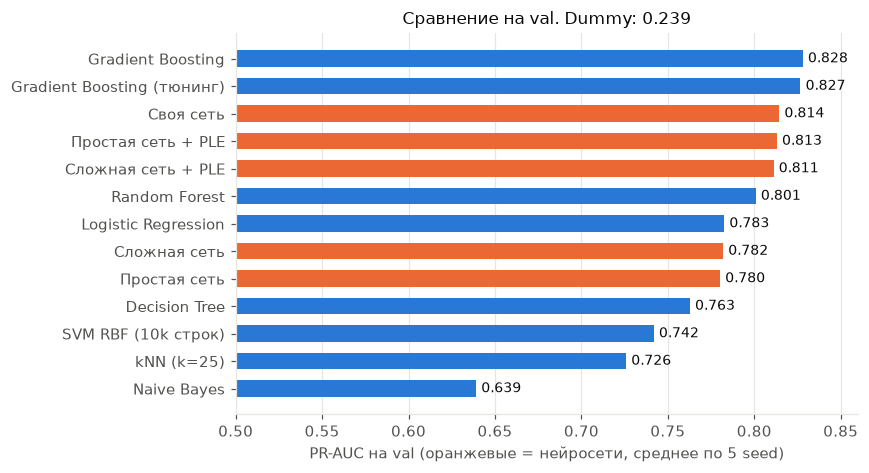

In [19]:
hgb_tuned = HistGradientBoostingClassifier(random_state=SEED, **best_hgb_params).fit(X_tr, y_train)
val_rows = [{"модель": r["модель"], "val PR-AUC": r["PR-AUC"], "val ROC-AUC": r["ROC-AUC"], "val F1": r["F1"]} for _, r in baseline_table.iterrows()]
s = hgb_tuned.predict_proba(X_va)[:, 1]
val_rows.append({"модель": "Gradient Boosting (тюнинг)", "val PR-AUC": average_precision_score(y_val, s), "val ROC-AUC": roc_auc_score(y_val, s),
                 "val F1": X.evaluate(y_val, s, X.best_threshold(y_val, s))["F1"]})
for k, runs in final_runs.items():
    f1 = [X.evaluate(y_val, r["val_scores"], X.best_threshold(y_val, r["val_scores"]))["F1"] for r in runs]
    val_rows.append({"модель": NAMES[k], "val PR-AUC": np.mean([average_precision_score(y_val, r["val_scores"]) for r in runs]),
                     "val ROC-AUC": np.mean([roc_auc_score(y_val, r["val_scores"]) for r in runs]), "val F1": np.mean(f1)})
val_cmp = pd.DataFrame(val_rows).sort_values("val PR-AUC", ascending=False).reset_index(drop=True)
val_cmp.to_csv(TABLES / "val_comparison.csv", index=False); display(val_cmp)

# Бустинг для сравнения выбираем тем же правилом: лучший на val из двух версий
BOOST = val_cmp[val_cmp["модель"].str.startswith("Gradient")].iloc[0]["модель"]
print("Бустинг для финального сравнения:", BOOST)

plot = val_cmp[~val_cmp["модель"].str.startswith("Dummy")].iloc[::-1]
colors = [ORANGE if m in NAMES.values() else BLUE for m in plot["модель"]]
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(plot["модель"], plot["val PR-AUC"], color=colors, height=0.6)
for y, v in enumerate(plot["val PR-AUC"]):
    ax.text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=9, color=TEXT)
ax.set_xlim(0.5, 0.86); ax.grid(axis="y", visible=False); ax.set_xlabel("PR-AUC на val (оранжевые = нейросети, среднее по 5 seed)")
ax.set_title(f"Сравнение на val. Dummy: {rate:.3f}")
plt.tight_layout(); plt.savefig(FIGURES / "val_comparison.png"); plt.show()

**Вывод.** По зафиксированному правилу лучшая модель это бустинг по умолчанию (0.828), лучшая сеть это своя сеть (0.814). Все сети с PLE обошли Random Forest. Выбор сделан, дальше test только измеряет.

## 9. Финальная оценка на test
Единственный проход по test. Выбор моделей и пороги уже зафиксированы на val и здесь не меняются.

In [20]:
def proba(run, inputs):
    return expit(T.predict_logits(T.restore(run), T.to_tensors(inputs)).numpy())

res_rows, test_scores = [], {}
for name in ["Logistic Regression", "Random Forest", "Gradient Boosting"]:
    pipe = base_scores[name][0]
    thr = X.best_threshold(y_val, M.scores_of(pipe, val_df))
    test_scores[name] = M.scores_of(pipe, test_df)
    res_rows.append({"модель": name, **X.evaluate(y_test, test_scores[name], thr), "std PR-AUC": np.nan})
thr = X.best_threshold(y_val, hgb_tuned.predict_proba(X_va)[:, 1])
test_scores["Gradient Boosting (тюнинг)"] = hgb_tuned.predict_proba(X_te)[:, 1]
res_rows.append({"модель": "Gradient Boosting (тюнинг)", **X.evaluate(y_test, test_scores["Gradient Boosting (тюнинг)"], thr), "std PR-AUC": np.nan})
dummy = base_scores["Dummy (частый класс)"][0]
res_rows.append({"модель": "Dummy (частый класс)", **X.evaluate(y_test, M.scores_of(dummy, test_df), 0.5), "std PR-AUC": 0.0})

own_thr = None
for k, runs in final_runs.items():
    seed_metrics = []
    for r in runs:
        thr = X.best_threshold(y_val, proba(r, FINAL_VAL[k]))
        seed_metrics.append(X.evaluate(y_test, proba(r, FINAL_TEST[k]), thr))
    sm = pd.DataFrame(seed_metrics)
    res_rows.append({"модель": NAMES[k], **sm.mean().to_dict(), "std PR-AUC": sm["PR-AUC"].std(ddof=0)})
    # Для кривых и bootstrap берём запуск seed 42: один реальный обученный экземпляр
    test_scores[NAMES[k]] = proba(runs[0], FINAL_TEST[k])
own_thr = X.best_threshold(y_val, proba(final_runs["own"][0], FINAL_VAL["own"]))
test_table = pd.DataFrame(res_rows).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
test_table.to_csv(TABLES / "test_results.csv", index=False); display(test_table)
torch.save({"state": final_runs["own"][0]["state"], "params": final_runs["own"][0]["params"]}, WEIGHTS / "own_nn_seed42.pt")

,модель,PR-AUC,ROC-AUC,F1,Precision,Recall,Accuracy,std PR-AUC
0,Gradient Boosting,0.831,0.931,0.735,0.742,0.727,0.874,NaN
1,Gradient Boosting (тюнинг),0.830,0.931,0.729,0.696,0.765,0.864,NaN
2,Своя сеть,0.820,0.926,0.723,0.666,0.792,0.855,0.002
3,Простая сеть + PLE,0.819,0.925,0.724,0.676,0.778,0.858,0.001
4,Сложная сеть + PLE,0.817,0.924,0.719,0.677,0.767,0.856,0.003
5,Random Forest,0.806,0.920,0.712,0.679,0.749,0.855,NaN
6,Logistic Regression,0.792,0.917,0.706,0.639,0.788,0.843,NaN
7,Сложная сеть,0.790,0.917,0.705,0.643,0.781,0.844,0.002
8,Простая сеть,0.789,0.917,0.706,0.639,0.788,0.843,0.001
9,Dummy (частый класс),0.239,0.500,0.000,0.000,0.000,0.761,0.000


**Вывод.** Порядок на test совпал с val, значит, переобучения под val нет. Бустинг: PR-AUC 0.831, ROC-AUC 0.931, F1 0.735. Своя сеть: PR-AUC 0.820 ± 0.002, ROC-AUC 0.926, F1 0.723. Простая сеть без PLE осталась на уровне логистической регрессии (0.789 и 0.792). Среди 100 человек с высоким доходом своя сеть находит 79, и 67 из 100 её срабатываний верны. Accuracy 0.855 ниже, чем 0.874 у бустинга, частично потому, что порог из val у сети сдвинут в сторону Recall.

### Значима ли разница
Парный bootstrap: одни и те же случайные выборки test для обеих моделей. Если 95% интервал содержит 0, разница не доказана.

In [21]:
pairs = [("Своя сеть", "Простая сеть"), ("Своя сеть", "Сложная сеть"), ("Своя сеть", "Простая сеть + PLE"),
         ("Своя сеть", "Сложная сеть + PLE"), (BOOST, "Своя сеть"), ("Своя сеть", "Logistic Regression")]
boot = pd.DataFrame([{"A": a, "B": b, **X.bootstrap_diff(y_test, test_scores[a], test_scores[b])} for a, b in pairs])
boot["разница доказана"] = (boot.ci_low > 0) | (boot.ci_high < 0)
boot.to_csv(TABLES / "bootstrap.csv", index=False); display(boot)

,A,B,разница,ci_low,ci_high,разница доказана
0,Своя сеть,Простая сеть,0.029,0.021,0.037,True
1,Своя сеть,Сложная сеть,0.027,0.019,0.034,True
2,Своя сеть,Простая сеть + PLE,-0.003,-0.007,0.001,False
3,Своя сеть,Сложная сеть + PLE,-0.002,-0.006,0.002,False
4,Gradient Boosting,Своя сеть,0.014,0.009,0.020,True
5,Своя сеть,Logistic Regression,0.026,0.018,0.033,True


**Вывод.** Доказано: своя сеть лучше простой и сложной без PLE (+0.029 и +0.027) и логистической регрессии (+0.026), а бустинг лучше своей сети (+0.014, интервал 0.009-0.020). Не доказано: что своя сеть лучше простой или сложной с PLE, интервалы содержат 0. Точечно своя сеть на seed 42 даже чуть ниже. Значит, на этих данных архитектура сверх двух слоёв не дала измеримой пользы, а вход дал.

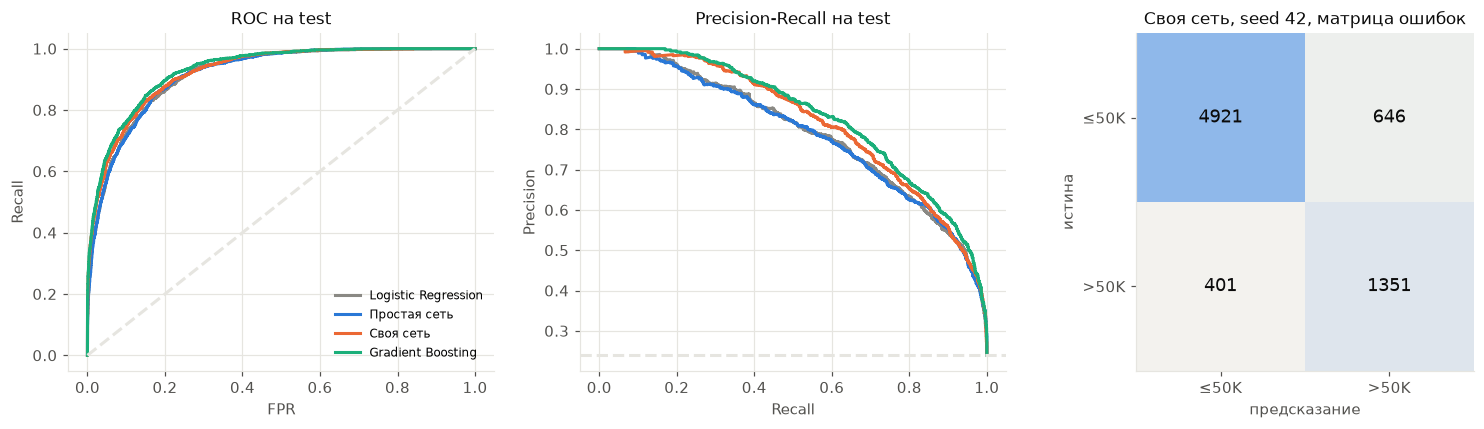

TN, FP, FN, TP = [4921, 646, 401, 1351] | порог из val: 0.36


In [22]:
# Кривые на test: 4 модели, от простого baseline к лучшим
show = [("Logistic Regression", GRAY), ("Простая сеть", BLUE), ("Своя сеть", ORANGE), (BOOST, AQUA)]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for name, color in show:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name]); axes[0].plot(fpr, tpr, color=color, label=name)
    p, r, _ = precision_recall_curve(y_test, test_scores[name]); axes[1].plot(r, p, color=color, label=name)
axes[0].plot([0, 1], [0, 1], color=GRID, linestyle="--"); axes[0].set(title="ROC на test", xlabel="FPR", ylabel="Recall")
axes[1].axhline(y_test.mean(), color=GRID, linestyle="--"); axes[1].set(title="Precision-Recall на test", xlabel="Recall", ylabel="Precision")
axes[0].legend(fontsize=8, loc="lower right")

y_pred_own = (test_scores["Своя сеть"] >= own_thr).astype(int)
cm = confusion_matrix(y_test, y_pred_own)
axes[2].imshow(cm, cmap=LinearSegmentedColormap.from_list("seq", ["#f3f2ee", "#8fb8ea"])); axes[2].grid(False)
axes[2].set_xticks([0, 1], ["≤50K", ">50K"]); axes[2].set_yticks([0, 1], ["≤50K", ">50K"])
axes[2].set(title="Своя сеть, seed 42, матрица ошибок", xlabel="предсказание", ylabel="истина")
for i in range(2):
    for j in range(2):
        axes[2].text(j, i, f"{cm[i, j]}", ha="center", va="center", color=TEXT, fontsize=12)
plt.tight_layout(); plt.savefig(FIGURES / "test_curves.png"); plt.show()
print("TN, FP, FN, TP =", cm.ravel().tolist(), "| порог из val:", round(own_thr, 3))

### Разбор ошибок по подгруппам
Общая метрика может скрывать, что модель по-разному ошибается для разных людей. В данных есть пол и раса, а перепись 1994 года содержит исторический разрыв в доходах.

In [23]:
sub = pd.concat([
    X.subgroup_table(y_test, y_pred_own, test_df["sex"]).assign(признак="sex"),
    X.subgroup_table(y_test, y_pred_own, test_df["race"]).assign(признак="race"),
])
sub.to_csv(TABLES / "subgroups.csv", index=False); display(sub)

# Какие ошибки сеть делает чаще всего: самые уверенные промахи
errors = test_df.assign(p=test_scores["Своя сеть"]).assign(err=lambda t: (t.p - t[D.TARGET]).abs()).nlargest(6, "err")
display(errors[["age", "education_num", "occupation", "marital_status", "hours_per_week", "capital_gain", D.TARGET, "p"]])

,группа,строк,доля >50K,предсказано >50K,Recall,FPR,Accuracy,признак
0,Male,4884,0.305,0.358,0.787,0.169,0.817,sex
1,Female,2435,0.107,0.102,0.681,0.033,0.936,sex
1,White,6279,0.255,0.292,0.779,0.125,0.851,race
0,Black,692,0.101,0.110,0.657,0.048,0.922,race
4,Asian-Pac-Islander,219,0.288,0.370,0.810,0.192,0.808,race
2,Amer-Indian-Eskimo,72,0.125,0.069,0.333,0.032,0.889,race
3,Other,57,0.158,0.070,0.444,0.000,0.912,race


,age,education_num,occupation,marital_status,hours_per_week,capital_gain,income_high,p
34710,51,13,Exec-managerial,Married-civ-spouse,40,0,0,0.999
32225,24,9,Other-service,Separated,50,0,1,0.001
22860,77,4,Adm-clerical,Married-spouse-absent,20,0,1,0.001
6034,30,9,Other-service,Separated,40,0,1,0.003
11143,28,9,Transport-moving,Never-married,45,0,1,0.004
45223,57,11,Prof-specialty,Married-civ-spouse,45,0,0,0.996


**Вывод.** Модель ошибается неодинаково. Женщины с высоким доходом находятся реже (Recall 0.68 против 0.79 у мужчин), зато ложных срабатываний меньше (FPR 0.03 против 0.17). То же у чернокожих респондентов: Recall 0.66 против 0.78. Для `Amer-Indian-Eskimo` (72 строки) и `Other` (57) числа ненадёжны: людей с высоким доходом там 9 и 9. Вероятная причина в том, что модель усвоила разницу базовых долей из данных 1994 года. Поэтому использовать её для решений о людях нельзя. Самые уверенные ошибки это женатые руководители с доходом ниже порога и люди без признаков высокого дохода, получающие выше: в анкете нет сведений об отрасли и регионе, поэтому такие ошибки трудно исправить.

### Что важно для модели
Permutation importance на val: перемешиваем один исходный столбец, пересчитываем зависящие от него новые признаки и смотрим, насколько упал PR-AUC. Сравниваем свою сеть и бустинг.

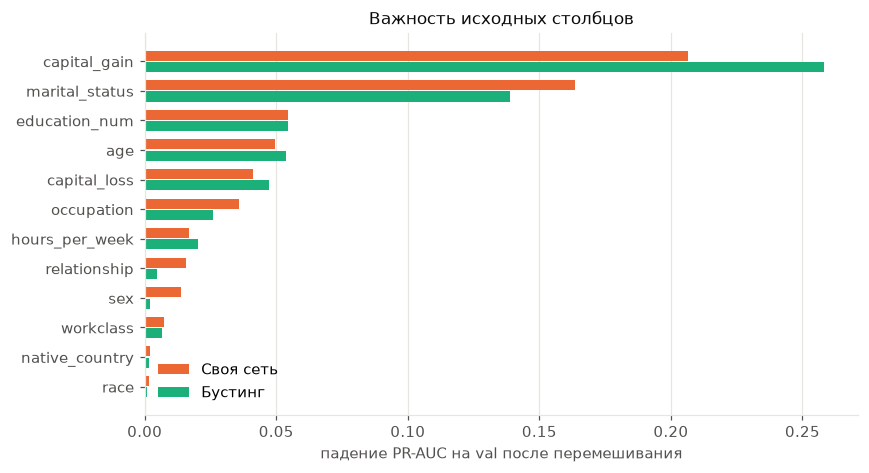

Топ-5 сеть: ['capital_gain', 'marital_status', 'education_num', 'age', 'capital_loss']
Топ-5 бустинг: ['capital_gain', 'marital_status', 'education_num', 'age', 'capital_loss']


,столбец,Своя сеть,Бустинг
3,capital_gain,0.206,0.258
6,marital_status,0.164,0.139
1,education_num,0.054,0.054
0,age,0.049,0.054
4,capital_loss,0.041,0.047
7,occupation,0.036,0.026
2,hours_per_week,0.017,0.020
8,relationship,0.016,0.005
10,sex,0.014,0.002
5,workclass,0.007,0.007


In [24]:
own_seed42 = T.restore(final_runs["own"][0])
def score_own(frame):
    x_num, x_cat = emb_pre.transform(frame)
    inputs = T.to_tensors([np.hstack([x_num, ple.transform(frame)]), x_cat])
    return expit(T.predict_logits(own_seed42, inputs).numpy())

def score_boost(frame):
    if BOOST == "Gradient Boosting":
        return base_scores[BOOST][0].predict_proba(frame)[:, 1]
    return hgb_tuned.predict_proba(onehot_pre["FE"].transform(frame).astype(np.float32))[:, 1]

val_clean = df_clean.loc[val_df.index]
base_cols = ["age", "education_num", "hours_per_week", "capital_gain", "capital_loss"] + D.CAT_COLS
rng = np.random.default_rng(SEED)
base_own, base_boost = average_precision_score(y_val, score_own(val_df)), average_precision_score(y_val, score_boost(val_df))
imp_rows = []
for col in base_cols:
    drops_own, drops_boost = [], []
    for _ in range(5):
        shuffled = val_clean.copy()
        shuffled[col] = rng.permutation(shuffled[col].to_numpy())
        frame = D.add_features(shuffled)  # производные признаки тоже должны потерять связь с целью
        drops_own.append(base_own - average_precision_score(y_val, score_own(frame)))
        drops_boost.append(base_boost - average_precision_score(y_val, score_boost(frame)))
    imp_rows.append({"столбец": col, "Своя сеть": np.mean(drops_own), "Бустинг": np.mean(drops_boost)})
imp = pd.DataFrame(imp_rows).sort_values("Своя сеть", ascending=False)
imp.to_csv(TABLES / "importance.csv", index=False)

plot = imp.iloc[::-1]; ypos = np.arange(len(plot))
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(ypos + 0.19, plot["Своя сеть"], height=0.34, color=ORANGE, label="Своя сеть")
ax.barh(ypos - 0.19, plot["Бустинг"], height=0.34, color=AQUA, label="Бустинг")
ax.set_yticks(ypos, plot["столбец"]); ax.grid(axis="y", visible=False); ax.legend()
ax.set_xlabel("падение PR-AUC на val после перемешивания"); ax.set_title("Важность исходных столбцов")
plt.tight_layout(); plt.savefig(FIGURES / "importance.png"); plt.show()
print("Топ-5 сеть:", imp.nlargest(5, "Своя сеть")["столбец"].tolist())
print("Топ-5 бустинг:", imp.nlargest(5, "Бустинг")["столбец"].tolist())
display(imp)

**Вывод.** Топ-5 у двух очень разных моделей совпал полностью: `capital_gain`, `marital_status`, `education_num`, `age`, `capital_loss`. Такая согласованность повышает доверие к объяснению. Различие: сеть сильнее опирается на `relationship` и `sex` (0.016 и 0.014 против 0.005 и 0.002), которые частично дублируют `marital_status`. Важность показывает, на что опирается модель, а не что является причиной дохода. `race` и `native_country` почти не влияют.

### Что выучили embeddings
Сеть получила профессии как индексы и не знала ничего об их смысле. Если embedding содержателен, профессии с похожим доходом окажутся рядом. Показываем векторы профессий в двух главных компонентах PCA.

|корреляция| главных компонент с долей >50K: PC1 0.34, PC2 0.43
Размер embedding occupation: (16, 8) | профессии: 14


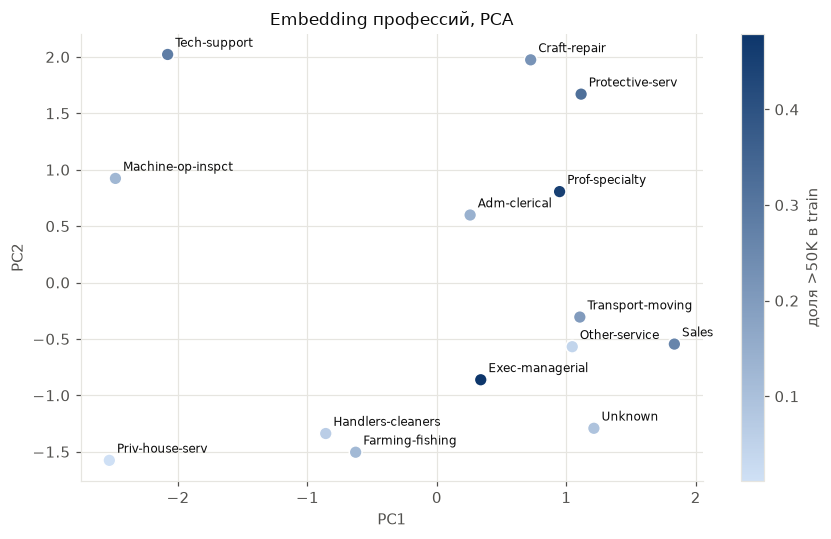

In [25]:
i_occ = D.CAT_COLS.index("occupation")
vectors = own_seed42.embeddings[i_occ].weight.detach().numpy()
names = emb_pre.category_names("occupation")
stat = train_df.groupby("occupation", observed=True)[D.TARGET].mean()
keep = [i for i, n in enumerate(names) if n in stat.index]  # служебный индекс <new> не показываем
coords = PCA(n_components=2, random_state=SEED).fit_transform(vectors[keep])
rates = np.array([stat[names[i]] for i in keep])
pc_corr = [abs(np.corrcoef(coords[:, c], rates)[0, 1]) for c in (0, 1)]
print(f"|корреляция| главных компонент с долей >50K: PC1 {pc_corr[0]:.2f}, PC2 {pc_corr[1]:.2f}")
print("Размер embedding occupation:", vectors.shape, "| профессии:", len(keep))
fig, ax = plt.subplots(figsize=(8, 5))
pts = ax.scatter(coords[:, 0], coords[:, 1], c=rates, cmap=LinearSegmentedColormap.from_list("seq", ["#cfe0f5", "#0d366b"]), s=70, edgecolor="white")
for (x, y), i in zip(coords, keep):
    ax.annotate(names[i], (x, y), xytext=(5, 5), textcoords="offset points", fontsize=8, color=TEXT)
fig.colorbar(pts, label="доля >50K в train"); ax.set(xlabel="PC1", ylabel="PC2", title="Embedding профессий, PCA")
plt.tight_layout(); plt.savefig(FIGURES / "embeddings_occupation.png"); plt.show()

**Вывод.** Осмысленные группы видны частично: рядом стоят `Handlers-cleaners` и `Farming-fishing`, а `Priv-house-serv` с самым низким доходом вынесена в угол. Однако прямой линии «доход» в двух компонентах нет: корреляция с долей >50K всего 0.34 и 0.43. Правдоподобное объяснение: прямой эффект профессии на доход проходит через wide-часть, а deep-части остаётся сложная часть зависимости. На 14 точках и одном seed это наблюдение, а не доказательство. С этим согласуется и ablation: заметного выигрыша от embeddings по сравнению с one-hot нет, зато они полезны для объяснения.

## 10. Вывод
| Пункт задания | Что сделано | Результат |
|---|---|---|
| 1. Датасет | Adult Census, 48 790 строк после очистки | Классы 24% на 76% |
| 2. Анализ и признаки | 6 вопросов EDA, 12 новых признаков | Сильны для линейной модели, не нужны бустингу |
| 3. Предобработка | Scaler, one-hot, embeddings, PLE только по train | Утечки нет |
| 4. Baseline | 7 моделей и Dummy | Лучший бустинг, test PR-AUC 0.831 |
| 5. Сети | Простая, сложная, своя | Своя сеть, test PR-AUC 0.820 ± 0.002 |

**Лучшая модель для этой задачи: бустинг** (доказано bootstrap: +0.014, интервал 0.009-0.020), к тому же он обучается за 2 секунды, а сеть почти за минуту. **Лучшая сеть: своя** на val, но её преимущество над простой сетью с PLE не доказано.

**Главный вывод работы.** Сеть проиграла не из-за нехватки слоёв, а из-за представления данных. Настройка размера давала тысячные доли, а одно изменение входа дало +0.03. Диагностика (разрыв без `capital_gain` сокращается в 4 раза) позволила найти это целенаправленно. Табличные данные с резкими порогами это сильная сторона деревьев, и результат согласуется с литературой (Grinsztajn и др., 2022).

**Ограничения.** Данные 1994 года из США, модель неодинаково ошибается по полу и расе, решения о людях на ней принимать нельзя. Поиск у своей сети шире (12 конфигураций против 3 и 6), а PLE и архитектура выбирались на одном val. Поэтому на val возможен небольшой оптимизм, но test его не показал. Малые группы по расе оценены ненадёжно.

**Что дальше:** настроить саму сеть с PLE (поиск делался до PLE), попробовать ансамбль сети и бустинга, проверить калибровку вероятностей.